Aditya discovered that stacking the widefield and time-averaged neuropixel data resulted in a better reconstruction with a subspace system identification method. The point of this method is to try this with various forms of DMD. Let $V\in\mathbb{R}^{50\times 500}$ be the first $50$ modes and first $500$ timepoints of the WF temporal component data and $N\in\mathbb{R}^{50\times 500}$ be the first $50$ PCA components and 500 time points of the time-averaged neuropixel data. We will compare the RSE in the reconstruction of V from a fit of $\begin{bmatrix} V \\ N \end{bmatrix}$ with the RSE in the reconstruction of $V$ from a fit of $V$, and do the same comparison from a fit of the joint data with a fit of just $N$.

A complication of this setup is that the time-averaging of the neuropixel data is equivalent to convolving the neuropixel data with a rectangular window. By the convolution theorem, this means that the Fourier transform of the time-averaged neuropixel data is the product of the Fourier transform of the raw data with the Fourier transform of the rectangular window. The Fourier transform of a rectangular window is a sinc function (in particular $\frac{2\sin Nk}{k}$ when the rectangular window function equals $1$ from $-N$ to $N$, and $0$ elsewhere), which has a peak near the origin and is nearly zero elsewhere. Thus time averaging essentially low pass filters the data, so the frequencies that DMD finds will not correspond to the true spiking frequencies. However, time window averaging (or some other kind of smoothing) is a necessary pre-processing step, as DMD will not fit discrete data with a reasonable number of modes. We will try to minimize the artifact by taking the averaging window to be as small as possible, and analyzing only the widefield data in the widefield+neuropixel stacks.

# Fitting OptDMD to Stack

In [1]:
import numpy as np # Matrix and vector algebra
import matplotlib.pylab as plt # Plotting
import pandas as pd # Tables
import warnings
from tqdm import tqdm # Progress bars
from sklearn.decomposition import PCA # PCA for comparisons
from BopDMD_Regularized import BOPDMD
from typing import Union,Type
from pydmd import HankelDMD
from pydmd.dmdoperator import DMDOperator

warnings.filterwarnings("ignore")
np.set_printoptions(suppress=True,precision=8,linewidth=100000) # Improve print statements
plt.rcParams['figure.dpi']=400 # Use higher resolution figures
plt.rcParams['text.usetex']=True # Use LaTeX in plots

In [2]:
RSE = lambda X,Y: np.sum((Y-np.real(X))**2)/np.sum((Y-np.mean(Y))**2)

# Create firing rates (sliding time-averaged neuropixel data)
B = 35
neuropixeldata   = np.load("../Mouse Data/spikes_v1_clean.npy")
num_times        = neuropixeldata.shape[1]
num_bins         = num_times-B # Create bins of width 35
rates            = np.zeros((336,num_bins))
for i in np.arange(num_bins):
    rates[:,i]     = np.sum(neuropixeldata[:,i:i+B],axis=1)/B # Average over sliding time window

# Get widefield data
SV = np.load('../Mouse Data/svdTemporalComponents_corr.npy').T

We will stack the first 1000 timepoints of the 50 Widefield temporal modes on top of the first 1000 timepoints of the 253 firing rates of neurons that fired at least once during the first 1000 timepoints.

We will also make a control: the first 1000 timepoints of the 50 widefield temporal modes stacked on top of the last 1000 timepoints of the 336 firing rates. Since this spike data will be occurring nearly an hour later, it should not have the same temporal dynamics as the widefield data.

We will also fit OptDMD to the unstacked datasets, to compare the error in the fits.

Finally, we will also introduce a time shift parameter to allow for the possibility that the fit is better when there is a slight time delay between the widefield and neuropixel data. This is very plausible for two reasons: 1) I believe neuropixel probes are inserted into the neuron's soma, and there is a slight delay between a neuron's soma depolarizing and calcium entering the axon terminal, and 2) the time window averaging means that each time point $t$ in the time-window averaged data contains information from time points $t,t-1,\ldots,t-B$ from the spike data, where $B$ is the length of the window ($35*0.0285s\approx 1s$ in this case).

Before stacking the data, we need to normalize the two datasets so that one does not dominate the other. The simplest way to do this would be to standardize each data matrix so that each feature has mean zero and standard deviation one. However, it seems wrong to me to standardize the widefield temporal component matrix, since we know a priori that the 50 components are arranged from most important to least important. On the other hand, there is nothing wrong with normalizing the neuropixel data matrix, since we do not have reason yet to believe that any one neuron is more important than any other neuron. So I have currently chosen to normalize the widefield data by setting its Frobenius norm to 1 and normalize the neuropixel matrix by setting each row (i.e. each neuron) to have $L_2$ norm one. It's definitely possible that a different normalization method might be better.

In [7]:
SV_norm = np.linalg.norm(SV)
SVn = SV / SV_norm
rates_norm = np.linalg.norm(rates,axis=1,keepdims=True)
rates_n = rates / rates_norm

def calculate_stack_error(start: int, stop: int, rank: int, V_timeshift: int, DMD_method: Type[DMDOperator],
                          d: int = None):
    # Indices of neurons that fired at least once during first (stop-start) timepoints
    fired         = np.nonzero(np.count_nonzero(rates_n[:,start:stop],axis=1))[0]
    # Indices of neurons that fired at least once during last (stop-start) timepoints
    fired_control = np.nonzero(np.count_nonzero(rates_n[:,-(stop-start):],axis=1))[0]
    
    # Shift time by V_timeshift indices for widefield data
    # Note: stopV-startV must equal stop-start for the stacking to work
    # (Negative indices can pose an issue here)
    startV = start + V_timeshift
    stopV  = stop + V_timeshift
    if startV < 0:
        raise ValueError("start+V_timeshift must be positive")

    # Widefield components stacked on time averaged NP data from same time period,
    # normalized to have Frobenius norm 1
    np_wf         = np.r_[SVn[:50,startV:stopV],rates_n[fired,start:stop]]
    np_wf_norm    = np.linalg.norm(np_wf)
    np_wf         = np_wf / np_wf_norm
    
    # Widefield components stacked on time averaged NP data from different time period,
    # again normalized to have Frobenius norm 1
    np_wf_control = np.r_[SVn[:50,startV:stopV],rates_n[fired_control,-(stop-start):]]
    np_wf_cnorm   = np.linalg.norm(np_wf_control)
    np_wf_control = np_wf_control / np_wf_cnorm
    stack         = DMD_method(int(rank))
    control       = DMD_method(int(rank))
    wf            = DMD_method(int(rank))

    if DMD_method is BOPDMD:
        stack.fit  (np_wf,                np.arange(stop-start))
        control.fit(np_wf_control,        np.arange(stop-start))
        wf.fit     (SVn[:50,startV:stopV],np.arange(stop-start))
    elif DMD_method is HankelDMD:
        stacked.fit(np_wf,d)
        control.fit(np_wf_control,d)
        wf.fit     (SVn[:50,startV:stopV],d)
    else:
        stacked.fit(np_wf)
        control.fit(np_wf_control)
        wf.fit     (SVn[:50,startV:stopV])
    
    stacked_wf_error = RSE(stack.reconstructed_data[:50]*np_wf_norm,SVn[:50,startV:stopV])
    control_wf_error = RSE(control.reconstructed_data[:50]*np_wf_cnorm,SVn[:50,startV:stopV])
    wf_only_error    = RSE(wf.reconstructed_data,SVn[:50,startV:stopV])
    
    return stacked_wf_error, control_wf_error, wf_only_error

This next function calculates the errors as a function of the number of modes or as a function of the timeshift. This gives us a clearer way to tell if fitting to one dataset is truly allowing the model to outperform fitting to a different dataset.

In [4]:
def get_stacked_optdmd_error(start: int, stop: int, modes: Union[np.ndarray,int],
                             timeshifts: Union[np.ndarray,int],DMD_method: Type[DMDOperator], d: int=None):
    stacked_wf_errors = []
    control_wf_errors = []
    wf_only_errors = []
    if isinstance(modes,np.ndarray) and isinstance(timeshifts,int):
        for i in tqdm(modes):
            errors = calculate_stack_error(start,stop,i,timeshifts,BOPDMD)
            stacked_wf_errors.append(errors[0])
            control_wf_errors.append(errors[1])
            wf_only_errors.append(errors[2])
    elif isinstance(timeshifts,np.ndarray) and isinstance(modes,int):
        for i in tqdm(timeshifts):
            errors = calculate_stack_error(start,stop,modes,i,BOPDMD)
            stacked_wf_errors.append(errors[0])
            control_wf_errors.append(errors[1])
            wf_only_errors.append(errors[2])
    else:
        raise ValueError("Error: Please specify one of modes or timeshifts as an array, and the other as a list.")
    return stacked_wf_errors,control_wf_errors,wf_only_errors

First let's try to determine an optimal shift for OptDMD in the range of -50 to 50 timesteps over the first 1000 timepoints with 24 modes (see the OptDMD overview notebook for an explanation on why 24 modes.)

In [24]:
errors = get_stacked_optdmd_error(100,1100,24,np.arange(-50,51),BOPDMD)

100%|█████████████████████████████████████████| 101/101 [01:46<00:00,  1.06s/it]


The next function handles plotting.

In [5]:
def plot_stacked_error(errors: tuple, modes: Union[np.ndarray,int], timeshifts: Union[np.ndarray,int], yerr: np.ndarray = None):
    stacked_wf_errors = errors[0]
    control_wf_errors = errors[1]
    wf_only_errors    = errors[2]
    if isinstance(modes,np.ndarray) and isinstance(timeshifts,int):
        x = modes
        plt.title("RSE of Fits to Stacks of Aligned or Misaligned WF+NP Data with Timeshift = " + str(timeshifts))
        plt.xlabel("Number of Modes")
    elif isinstance(timeshifts,np.ndarray) and isinstance(modes,int):
        x = timeshifts
        plt.title("RSE of Fits to Stacks of Aligned or Misaligned WF+NP Data with " + str(modes) + " Modes")
        plt.xlabel("Widefield Timeshift")
    plt.plot(x,stacked_wf_errors,label="Aligned WF")
    plt.plot(x,control_wf_errors,label="Misaligned WF")
    plt.plot(x,wf_only_errors,label="WF Only")
    if yerr is not None:
        stacked_err = yerr[0]
        control_err = yerr[1]
        wf_only_err = yerr[2]
        plt.fill_between(x,stacked_wf_errors-stacked_err,stacked_wf_errors+stacked_err,alpha=0.5)
        plt.fill_between(x,control_wf_errors-control_err,control_wf_errors+control_err,alpha=0.5)
        plt.fill_between(x,wf_only_errors-wf_only_err,wf_only_errors+wf_only_err,alpha=0.5)
    plt.legend()
    plt.ylabel("RSE")
    plt.yscale('log')

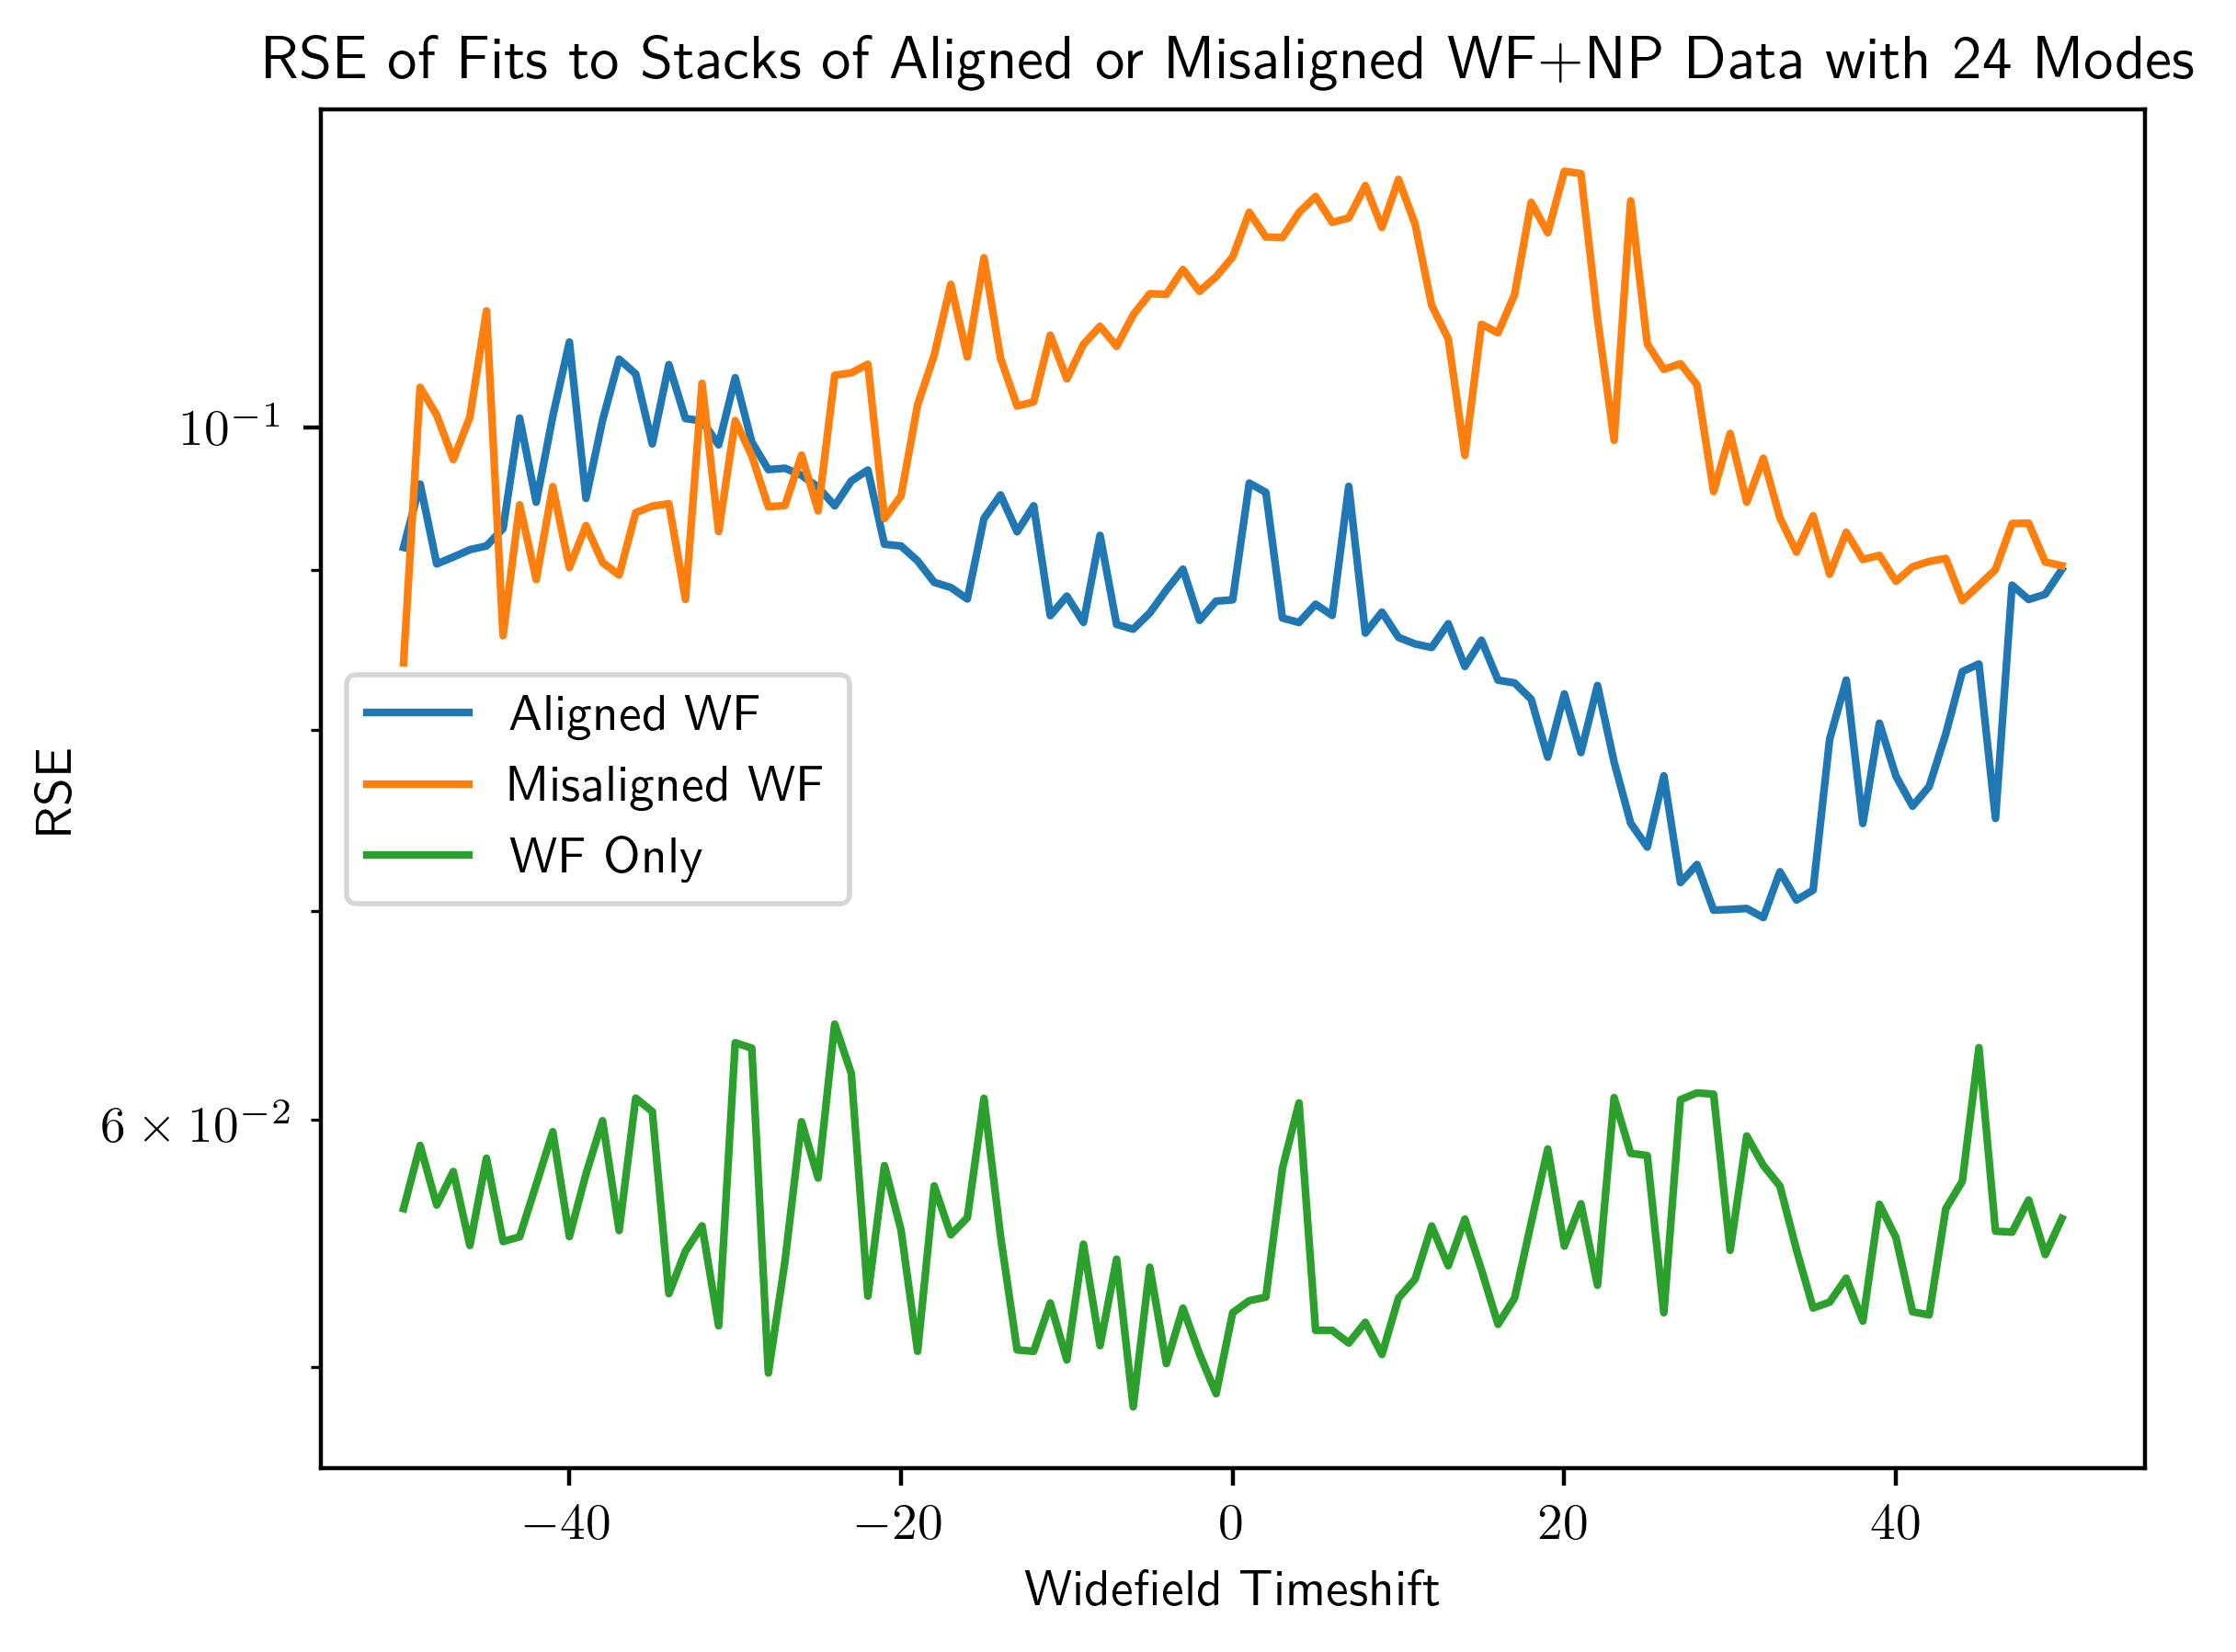

In [26]:
plot_stacked_error(errors,24,np.arange(-50,51))

The misaligned widefield data seems to perform a little worse than the aligned widefield data across most timeshifts. This trend only really breaks down with negative timeshifts; presumably both datasets are misaligned there. The aligned stacked data also seems to perform a little worse than the widefield only data, but the performance gets better with a timeshift of about 30 timepoints. Let's see if this trend of the 30 timepoint shift outperforming the misaligned data holds with different numbers of modes and on different time windows.

In [29]:
errors_30 = get_stacked_optdmd_error(100,1100,np.arange(5,40),30,BOPDMD)

100%|███████████████████████████████████████████| 35/35 [00:35<00:00,  1.01s/it]


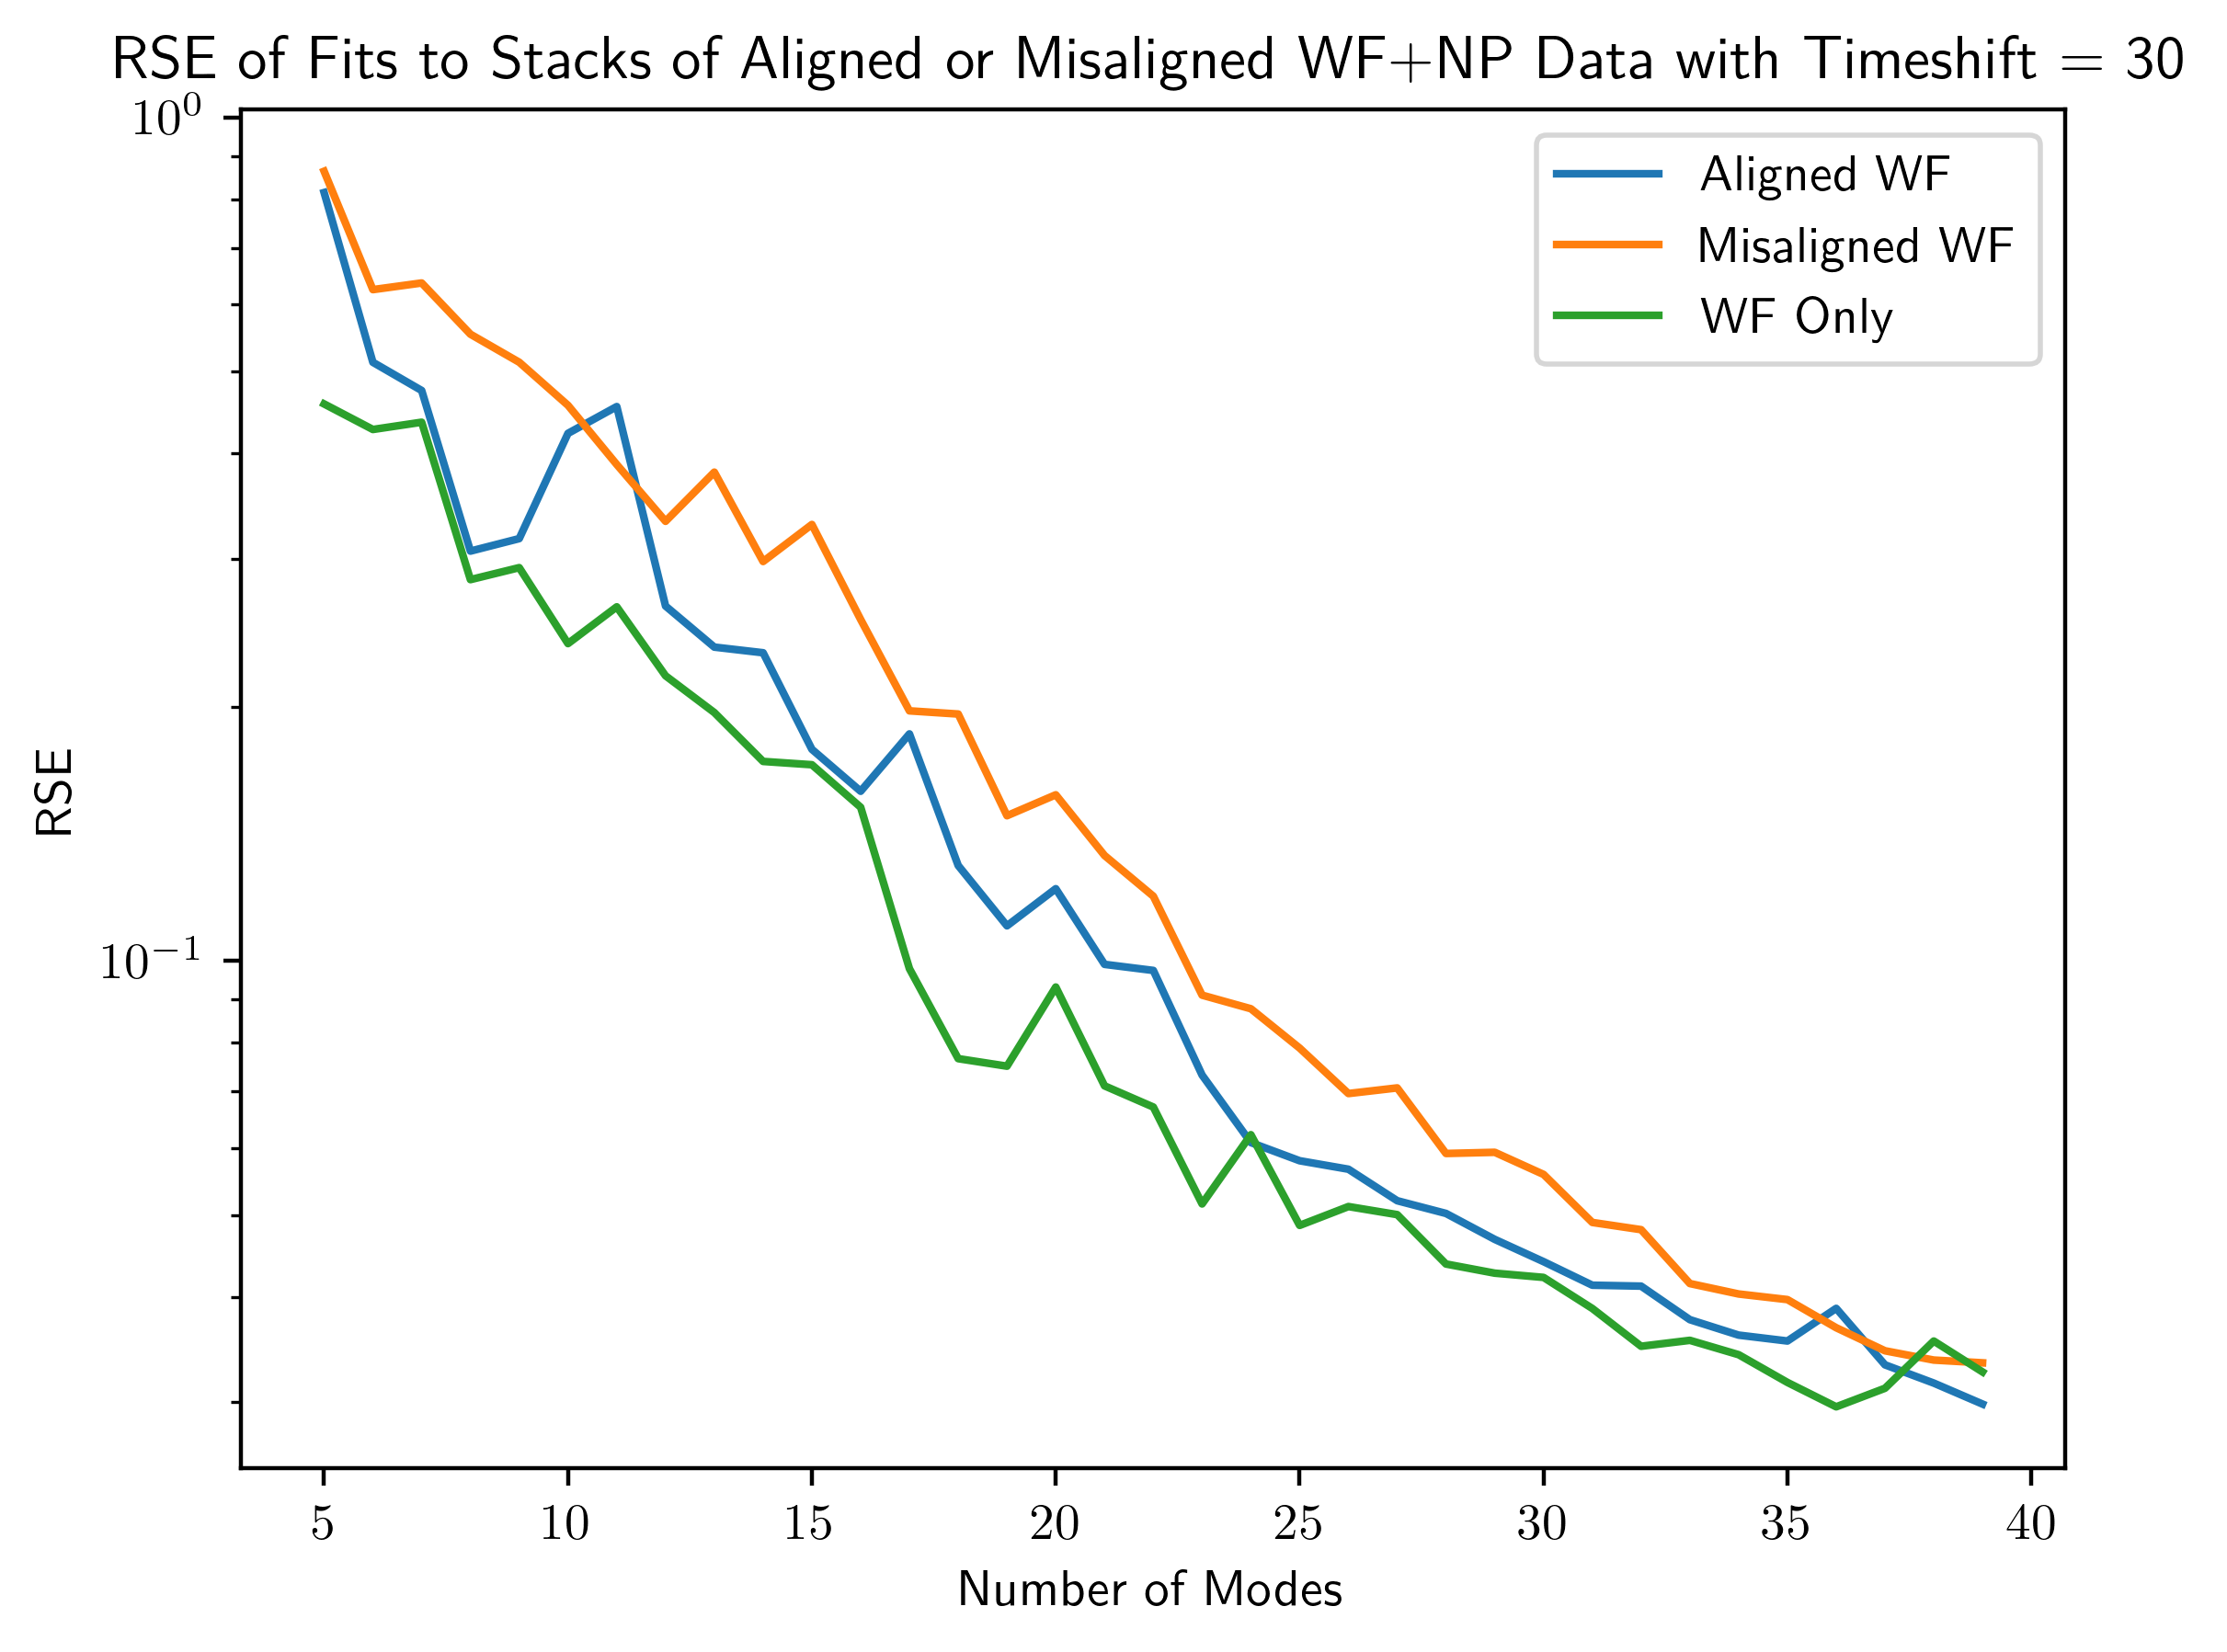

In [30]:
plot_stacked_error(errors_25,np.arange(5,40),30)

There does seem to be outperformance of the aligned data around the rank predicted by the optimal hard SVD threshold (24), but let's see if it's statistically significant. We'll fit on 20 different non-overlapping windows and compute the mean errors and the SEMs.

In [104]:
n = 30
total_errors = np.zeros((26,3,n))
for i in range(1,n+1):
    errors = get_stacked_optdmd_error(i*1000,(i+1)*1000,np.arange(5,31),30,BOPDMD)
    for j in range(3):
        total_errors[:,j,i-1] = errors[j]

100%|███████████████████████████████████████████| 26/26 [00:28<00:00,  1.09s/it]


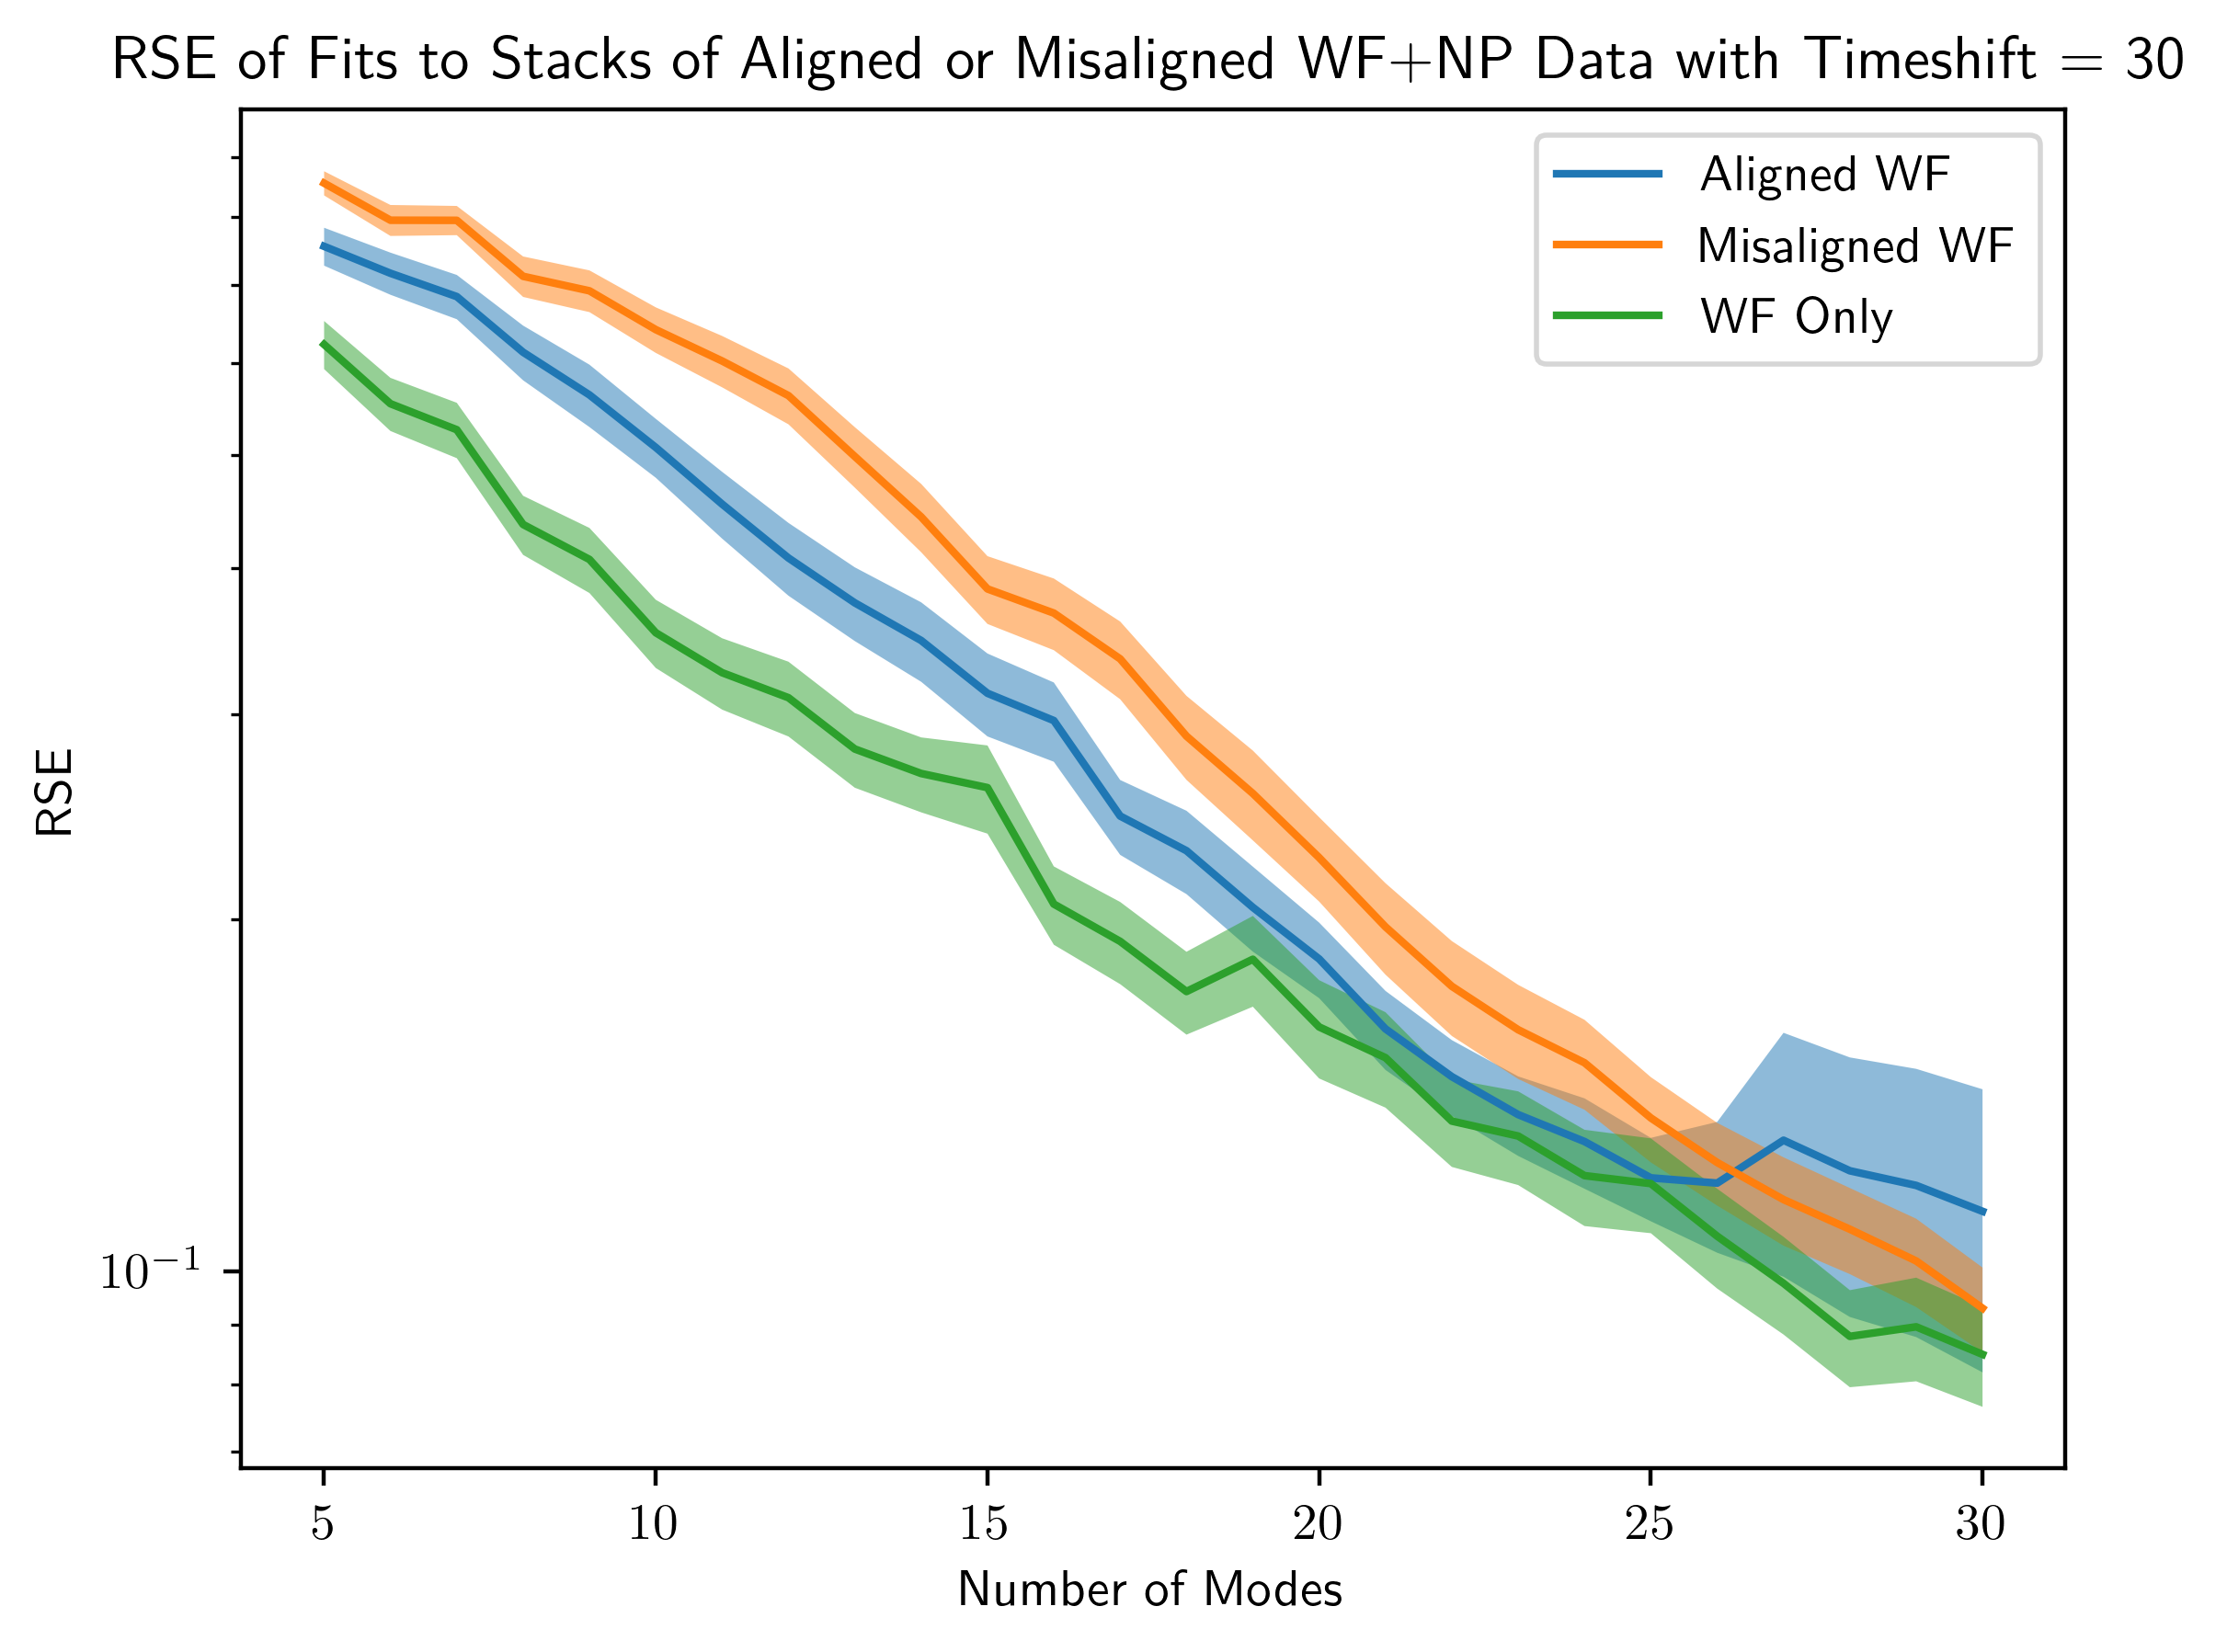

In [105]:
plot_stacked_error(np.mean(total_errors,axis=2).T,np.arange(5,31),30,np.std(total_errors,axis=2).T/np.sqrt(n))

The plot seems to indicate that the aligned data has significantly lower error than the misaligned data up to a point, as the aligned WF and misaligned WF error regions initially do not touch. Let's do a dependent t-test for each mode to show this conclusively. Here the null hypothesis is that the RSE of the aligned WF is greater than or equal to the RSE of the misaligned WF for the given number of modes. The alternative hypothesis is that the RSE of the aligned WF is less than the RSE of the misaligned WF for the given number of modes. The reason to do a dependent t-test vs an independent t-test is that the misaligned and aligned samples are not entirely independent, since the first sample of both is a fit to the first 1000 timepoints, the second sample of both is a fit to the second 1000 timepoints, etc.

Text(0.5, 1.0, 'One-sided Dependent t-test for Aligned RSE $<$ Misaligned RSE')

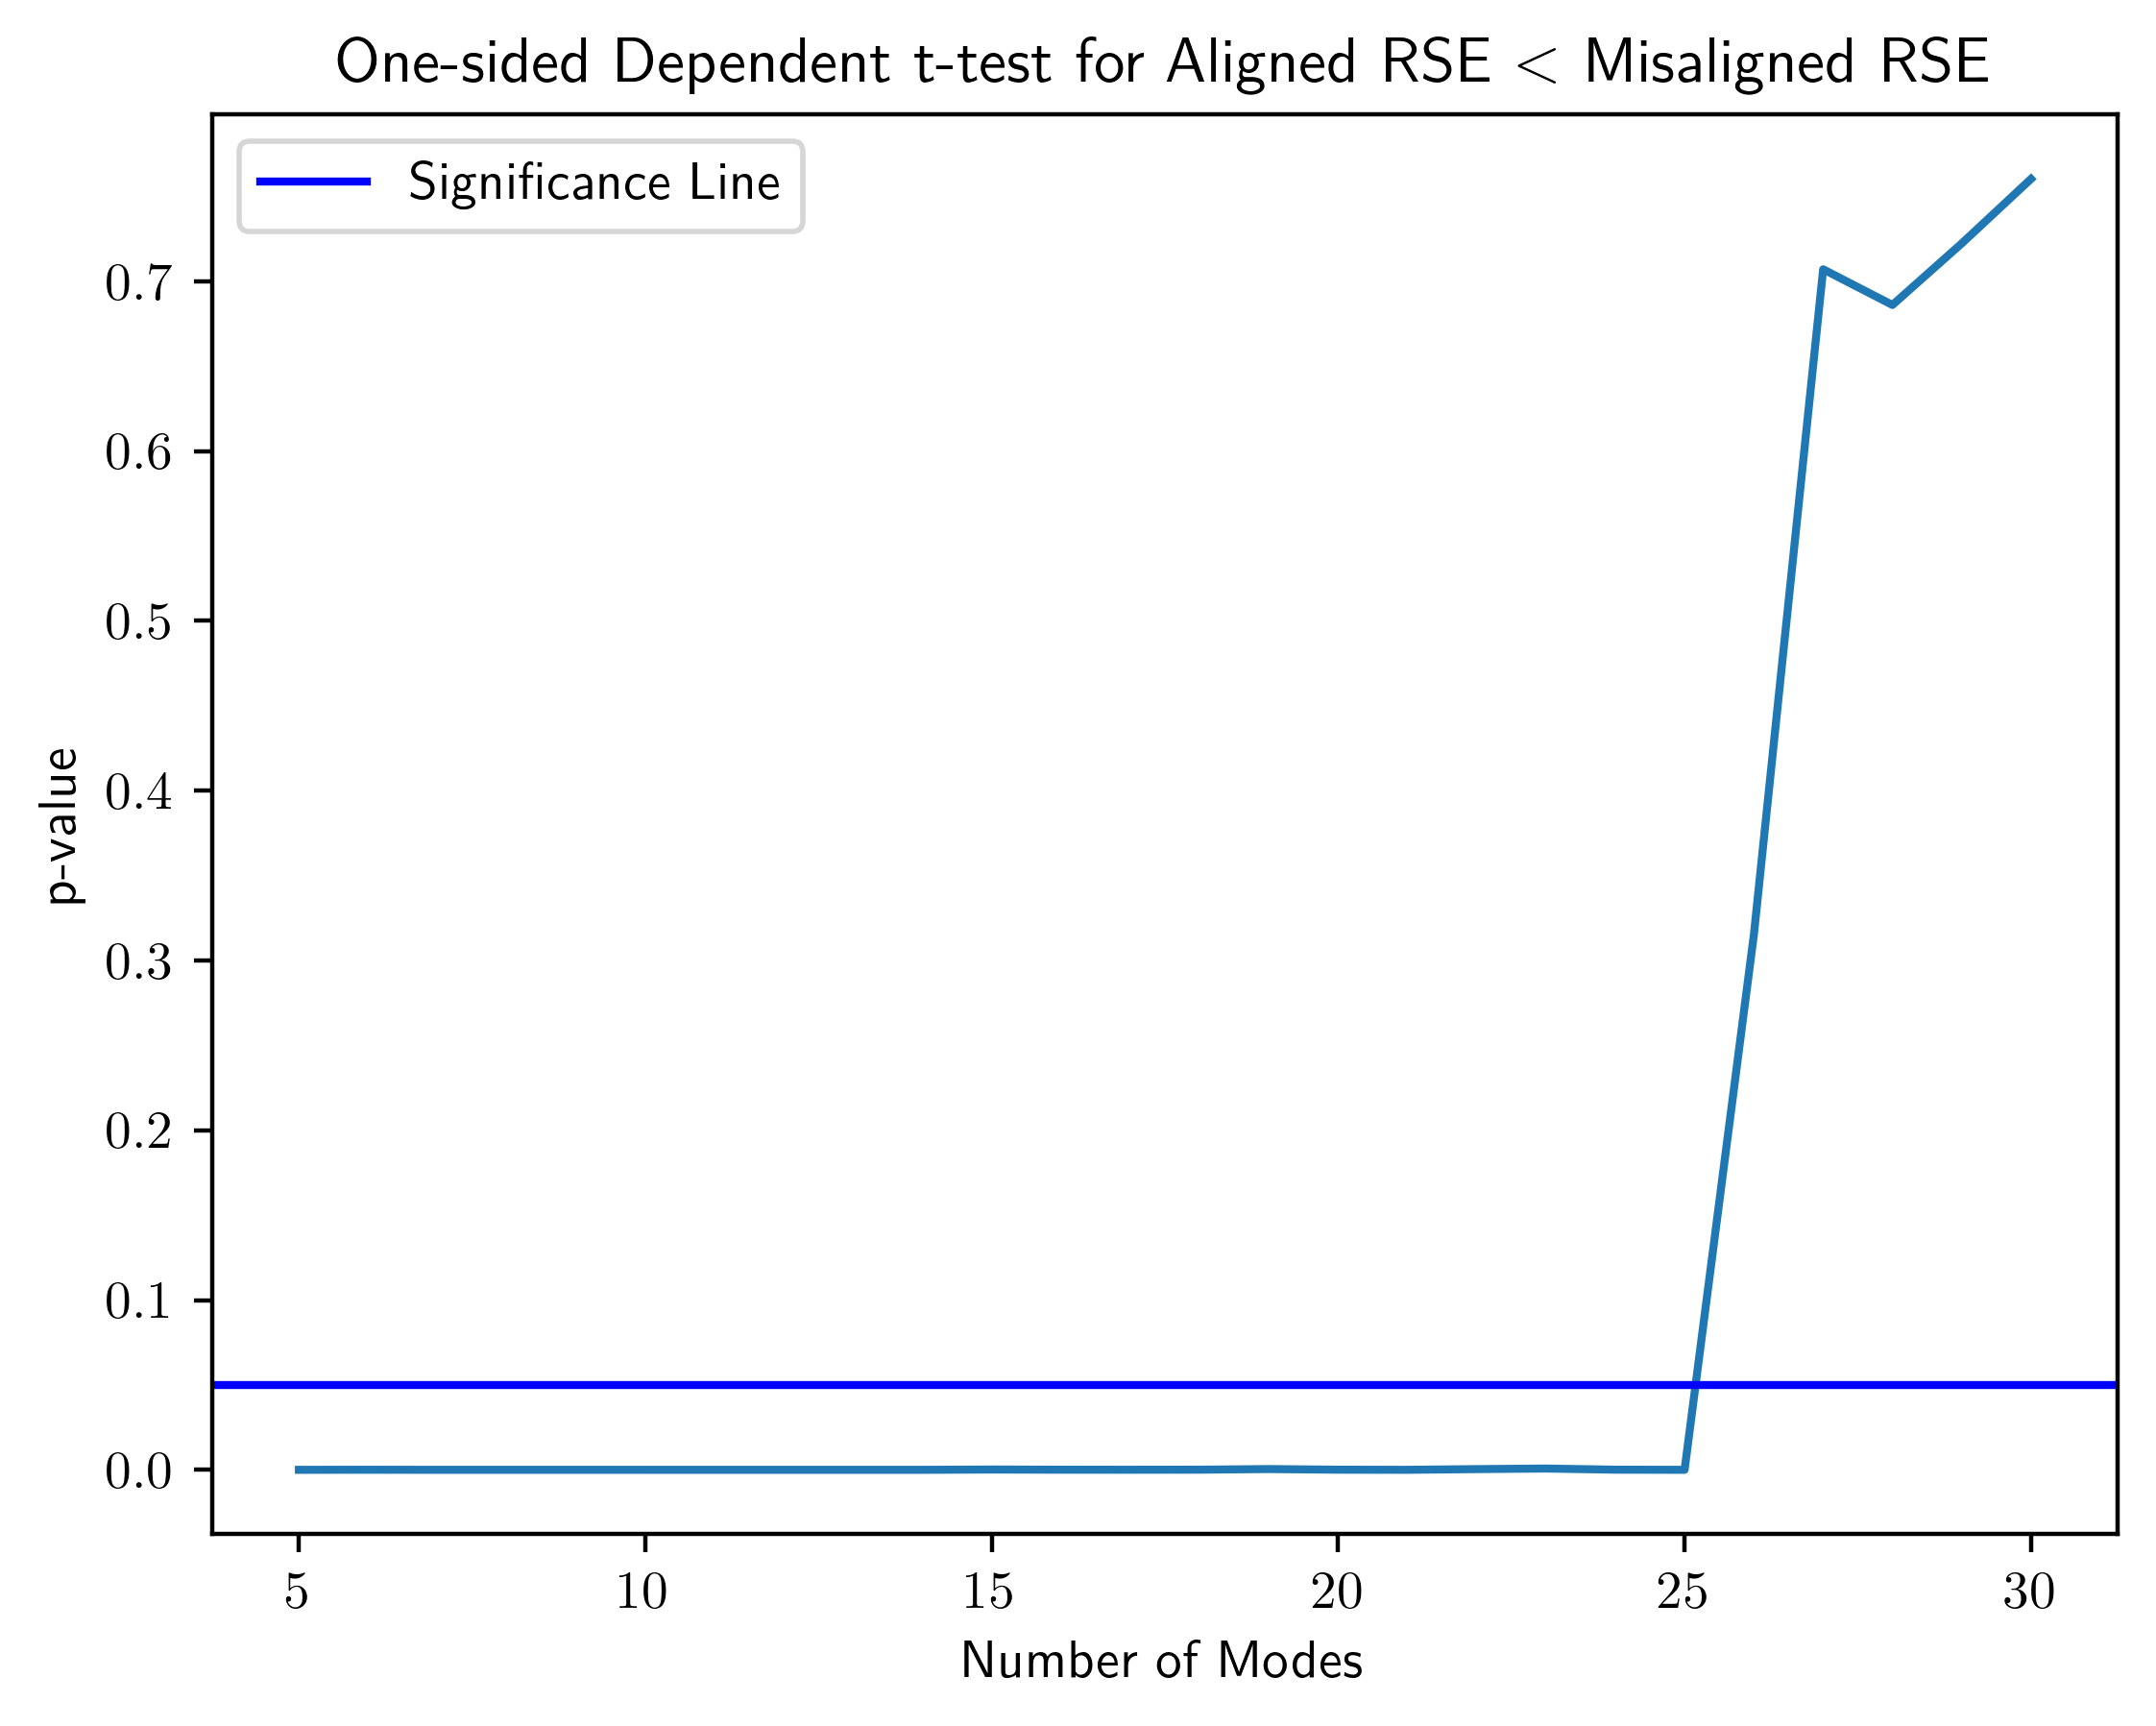

In [106]:
from scipy.stats import ttest_rel
p_values = ttest_rel(total_errors[:,0,:].T,total_errors[:,1,:].T,alternative='less')[1]
plt.plot(np.arange(5,31),p_values)
plt.axhline(0.05,label="Significance Line",color='blue')
plt.xlabel("Number of Modes")
plt.ylabel("p-value")
plt.legend()
plt.title("One-sided Dependent t-test for Aligned RSE $<$ Misaligned RSE")

The aligned fit is significantly better than the unaligned fit up until 26 modes, at which point OptDMD is able to fit both datasets independently. Let's look at whether or not the aligned RSE is significantly larger than the widefield only RSE.

Text(0.5, 1.0, 'One-sided Dependent t-test for Widefield RSE $<$ Aligned RSE')

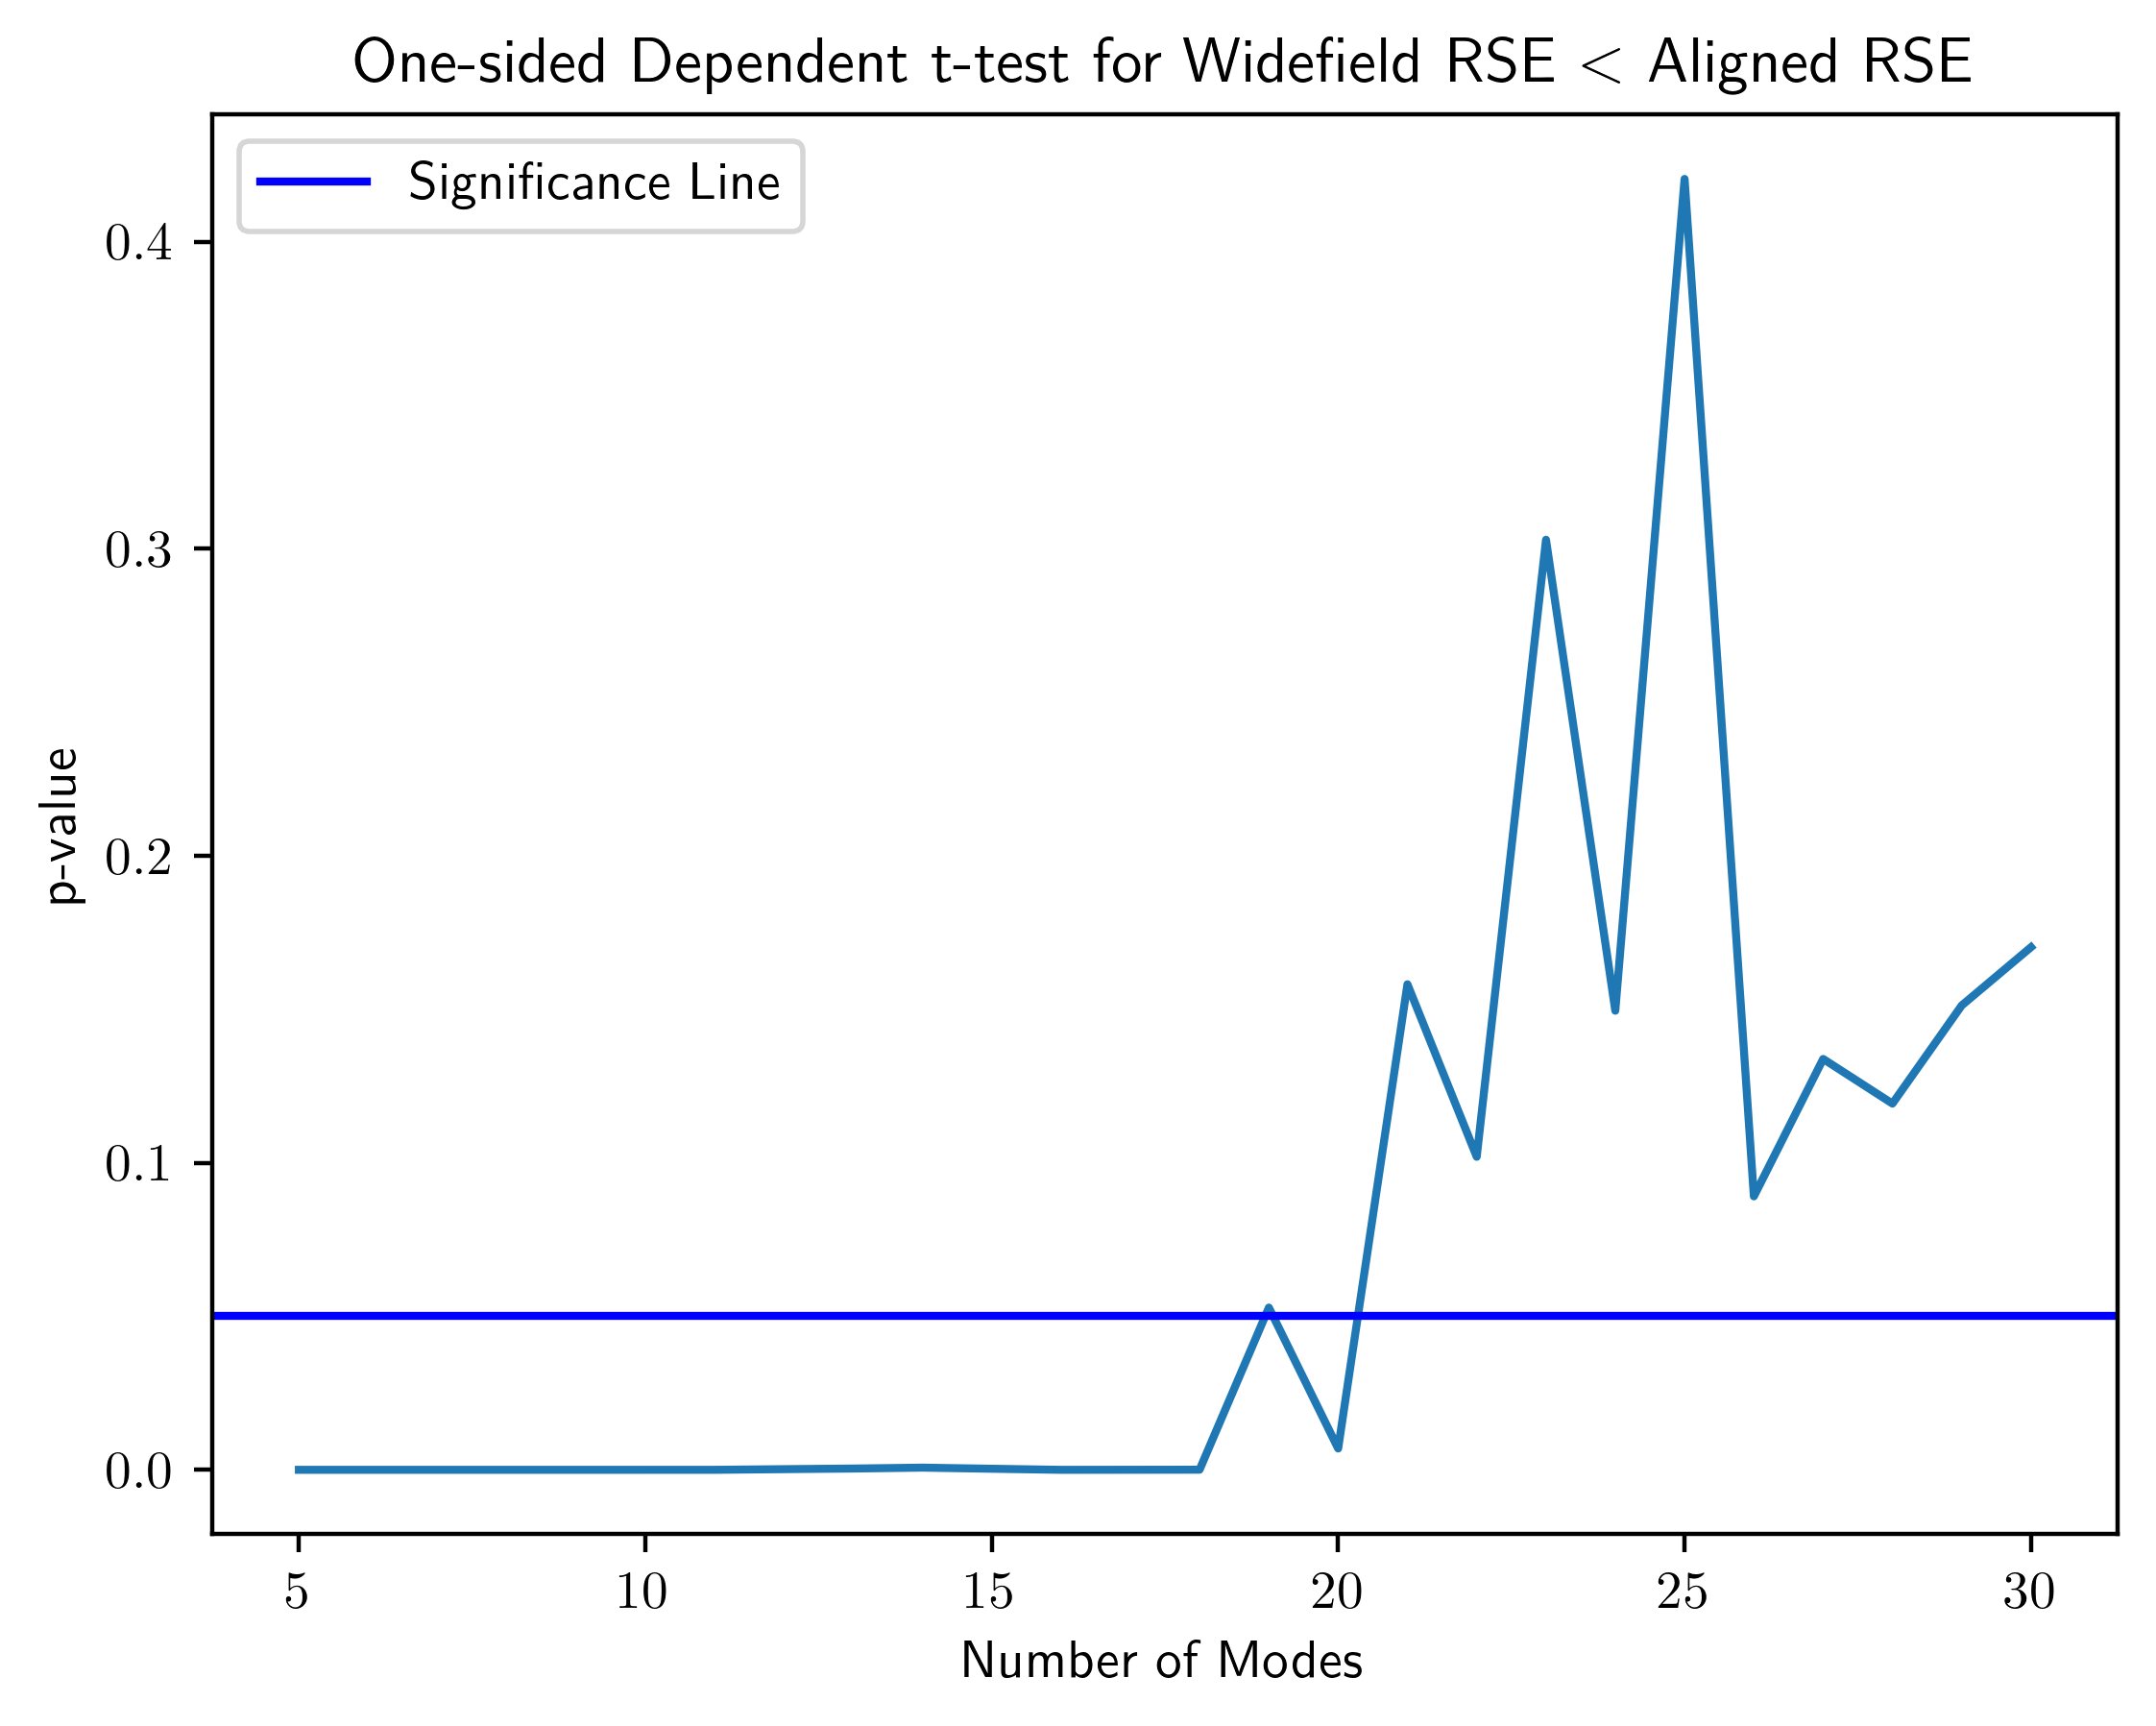

In [110]:
from scipy.stats import ttest_rel
p_values = ttest_rel(total_errors[:,2,:].T,total_errors[:,0,:].T,alternative='less')[1]
plt.plot(np.arange(5,31),p_values)
plt.axhline(0.05,label="Significance Line",color='blue')
plt.xlabel("Number of Modes")
plt.ylabel("p-value")
plt.legend()
plt.title("One-sided Dependent t-test for Widefield RSE $<$ Aligned RSE")

Around 21+ modes, the aligned RSE stops being significantly higher than the widefield only RSE.

Now let's repeat this analysis with HankelDMD.

In [8]:
n = 30
total_errors = np.zeros((26,3,n))
for i in range(1,n+1):
    errors = get_stacked_optdmd_error(i*1000,(i+1)*1000,np.arange(5,31),30,HankelDMD,d=500)
    for j in range(3):
        total_errors[:,j,i-1] = errors[j]

100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 26/26 [00:51<00:00,  1.98s/it]


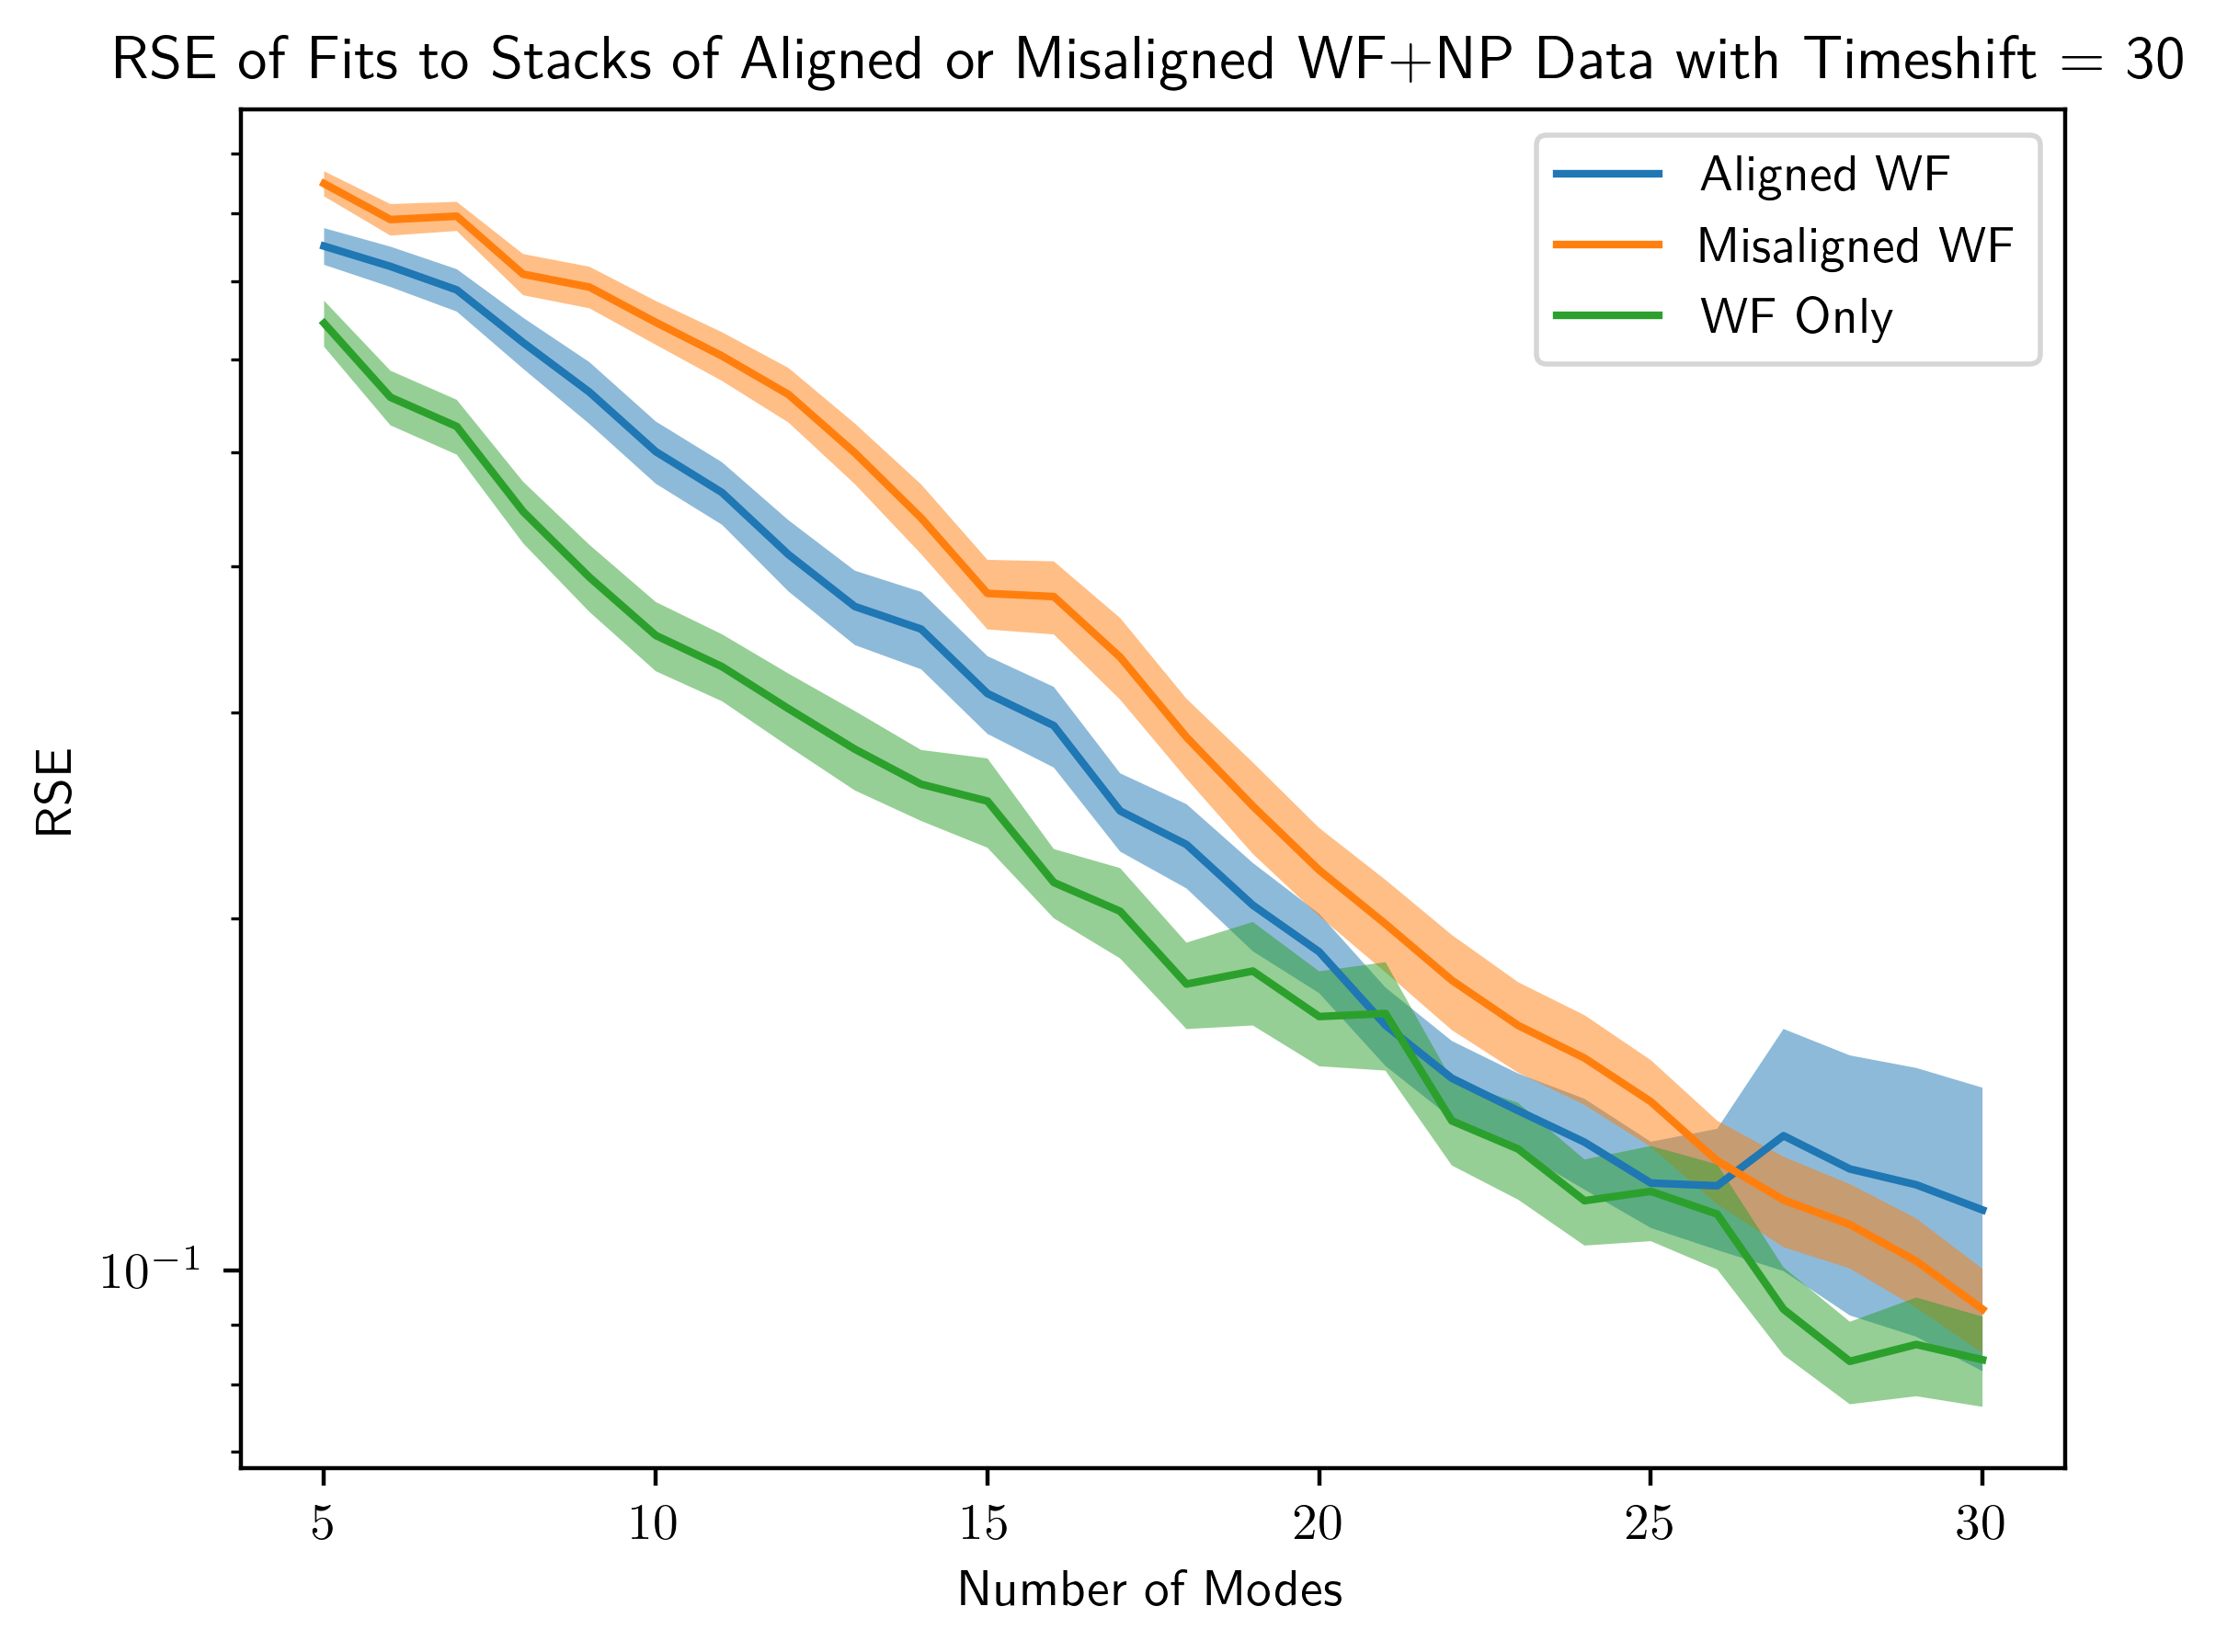

In [9]:
plot_stacked_error(np.mean(total_errors,axis=2).T,np.arange(5,31),30,np.std(total_errors,axis=2).T/np.sqrt(n))

Text(0.5, 1.0, 'One-sided Dependent t-test for Aligned RSE $<$ Misaligned RSE (HankelDMD)')

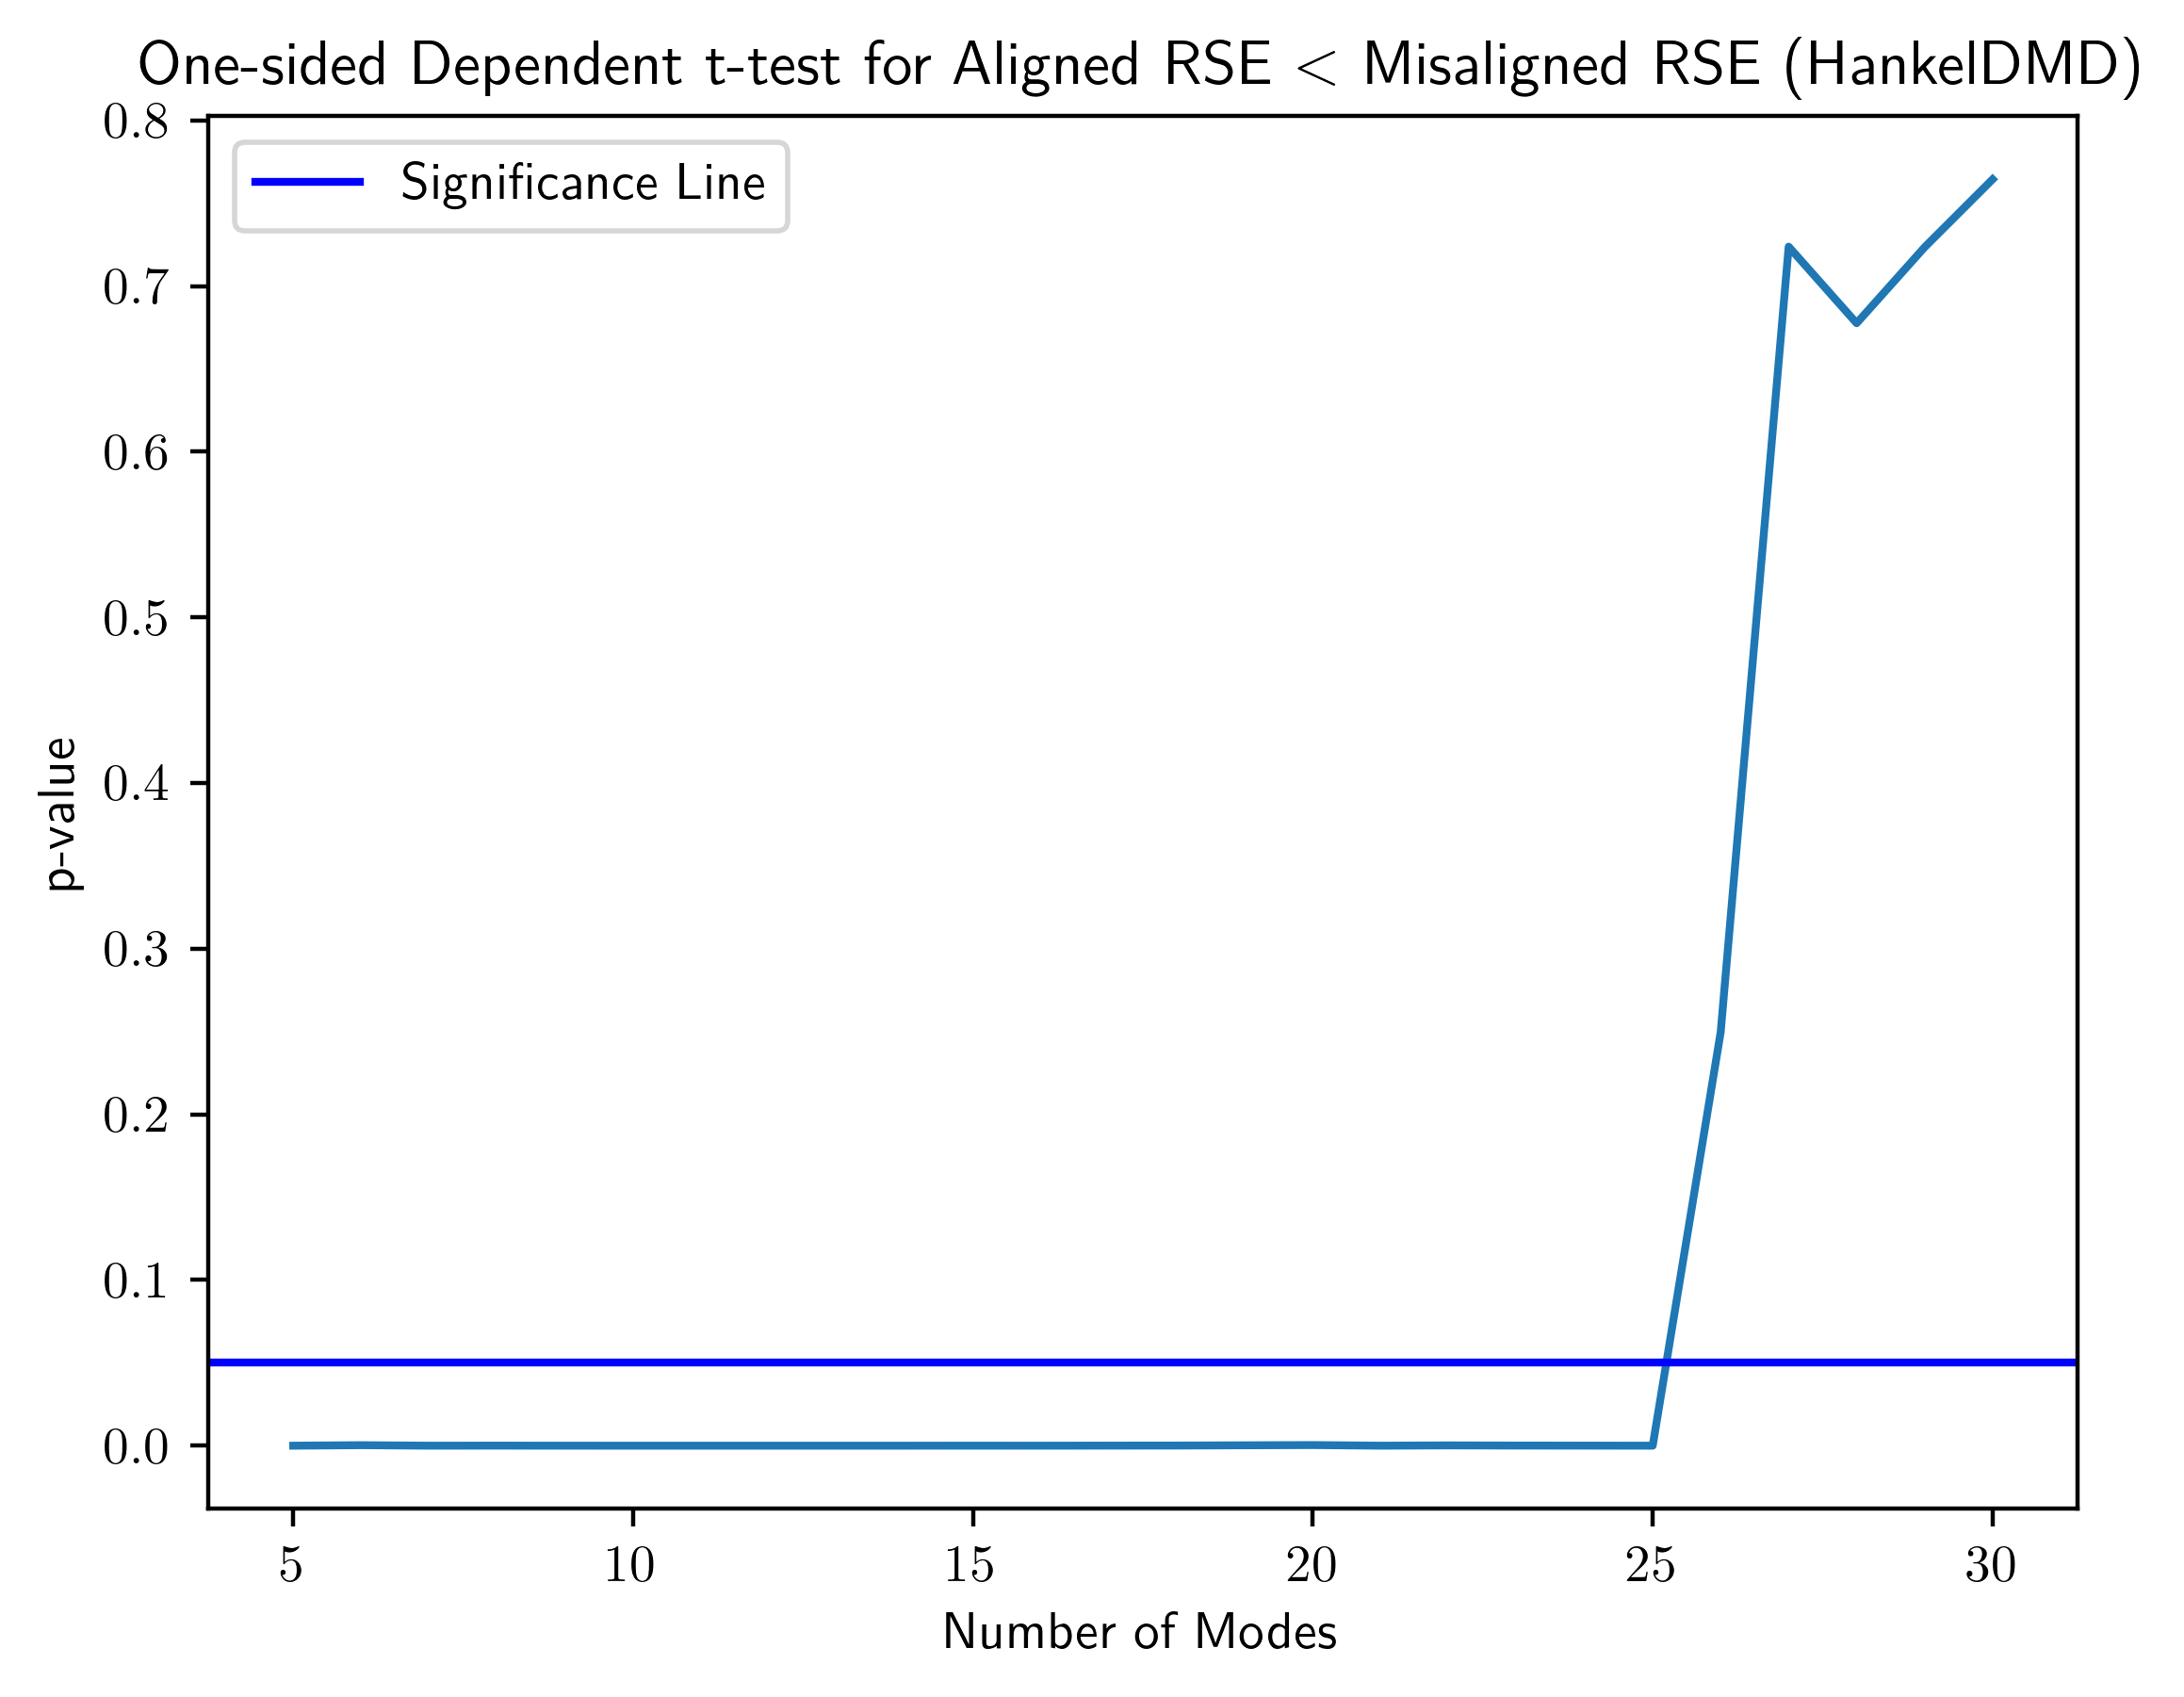

In [10]:
from scipy.stats import ttest_rel
p_values = ttest_rel(total_errors[:,0,:].T,total_errors[:,1,:].T,alternative='less')[1]
plt.plot(np.arange(5,31),p_values)
plt.axhline(0.05,label="Significance Line",color='blue')
plt.xlabel("Number of Modes")
plt.ylabel("p-value")
plt.legend()
plt.title("One-sided Dependent t-test for Aligned RSE $<$ Misaligned RSE (HankelDMD)")

Text(0.5, 1.0, 'One-sided Dependent t-test for Widefield RSE $<$ Aligned RSE (HankelDMD)')

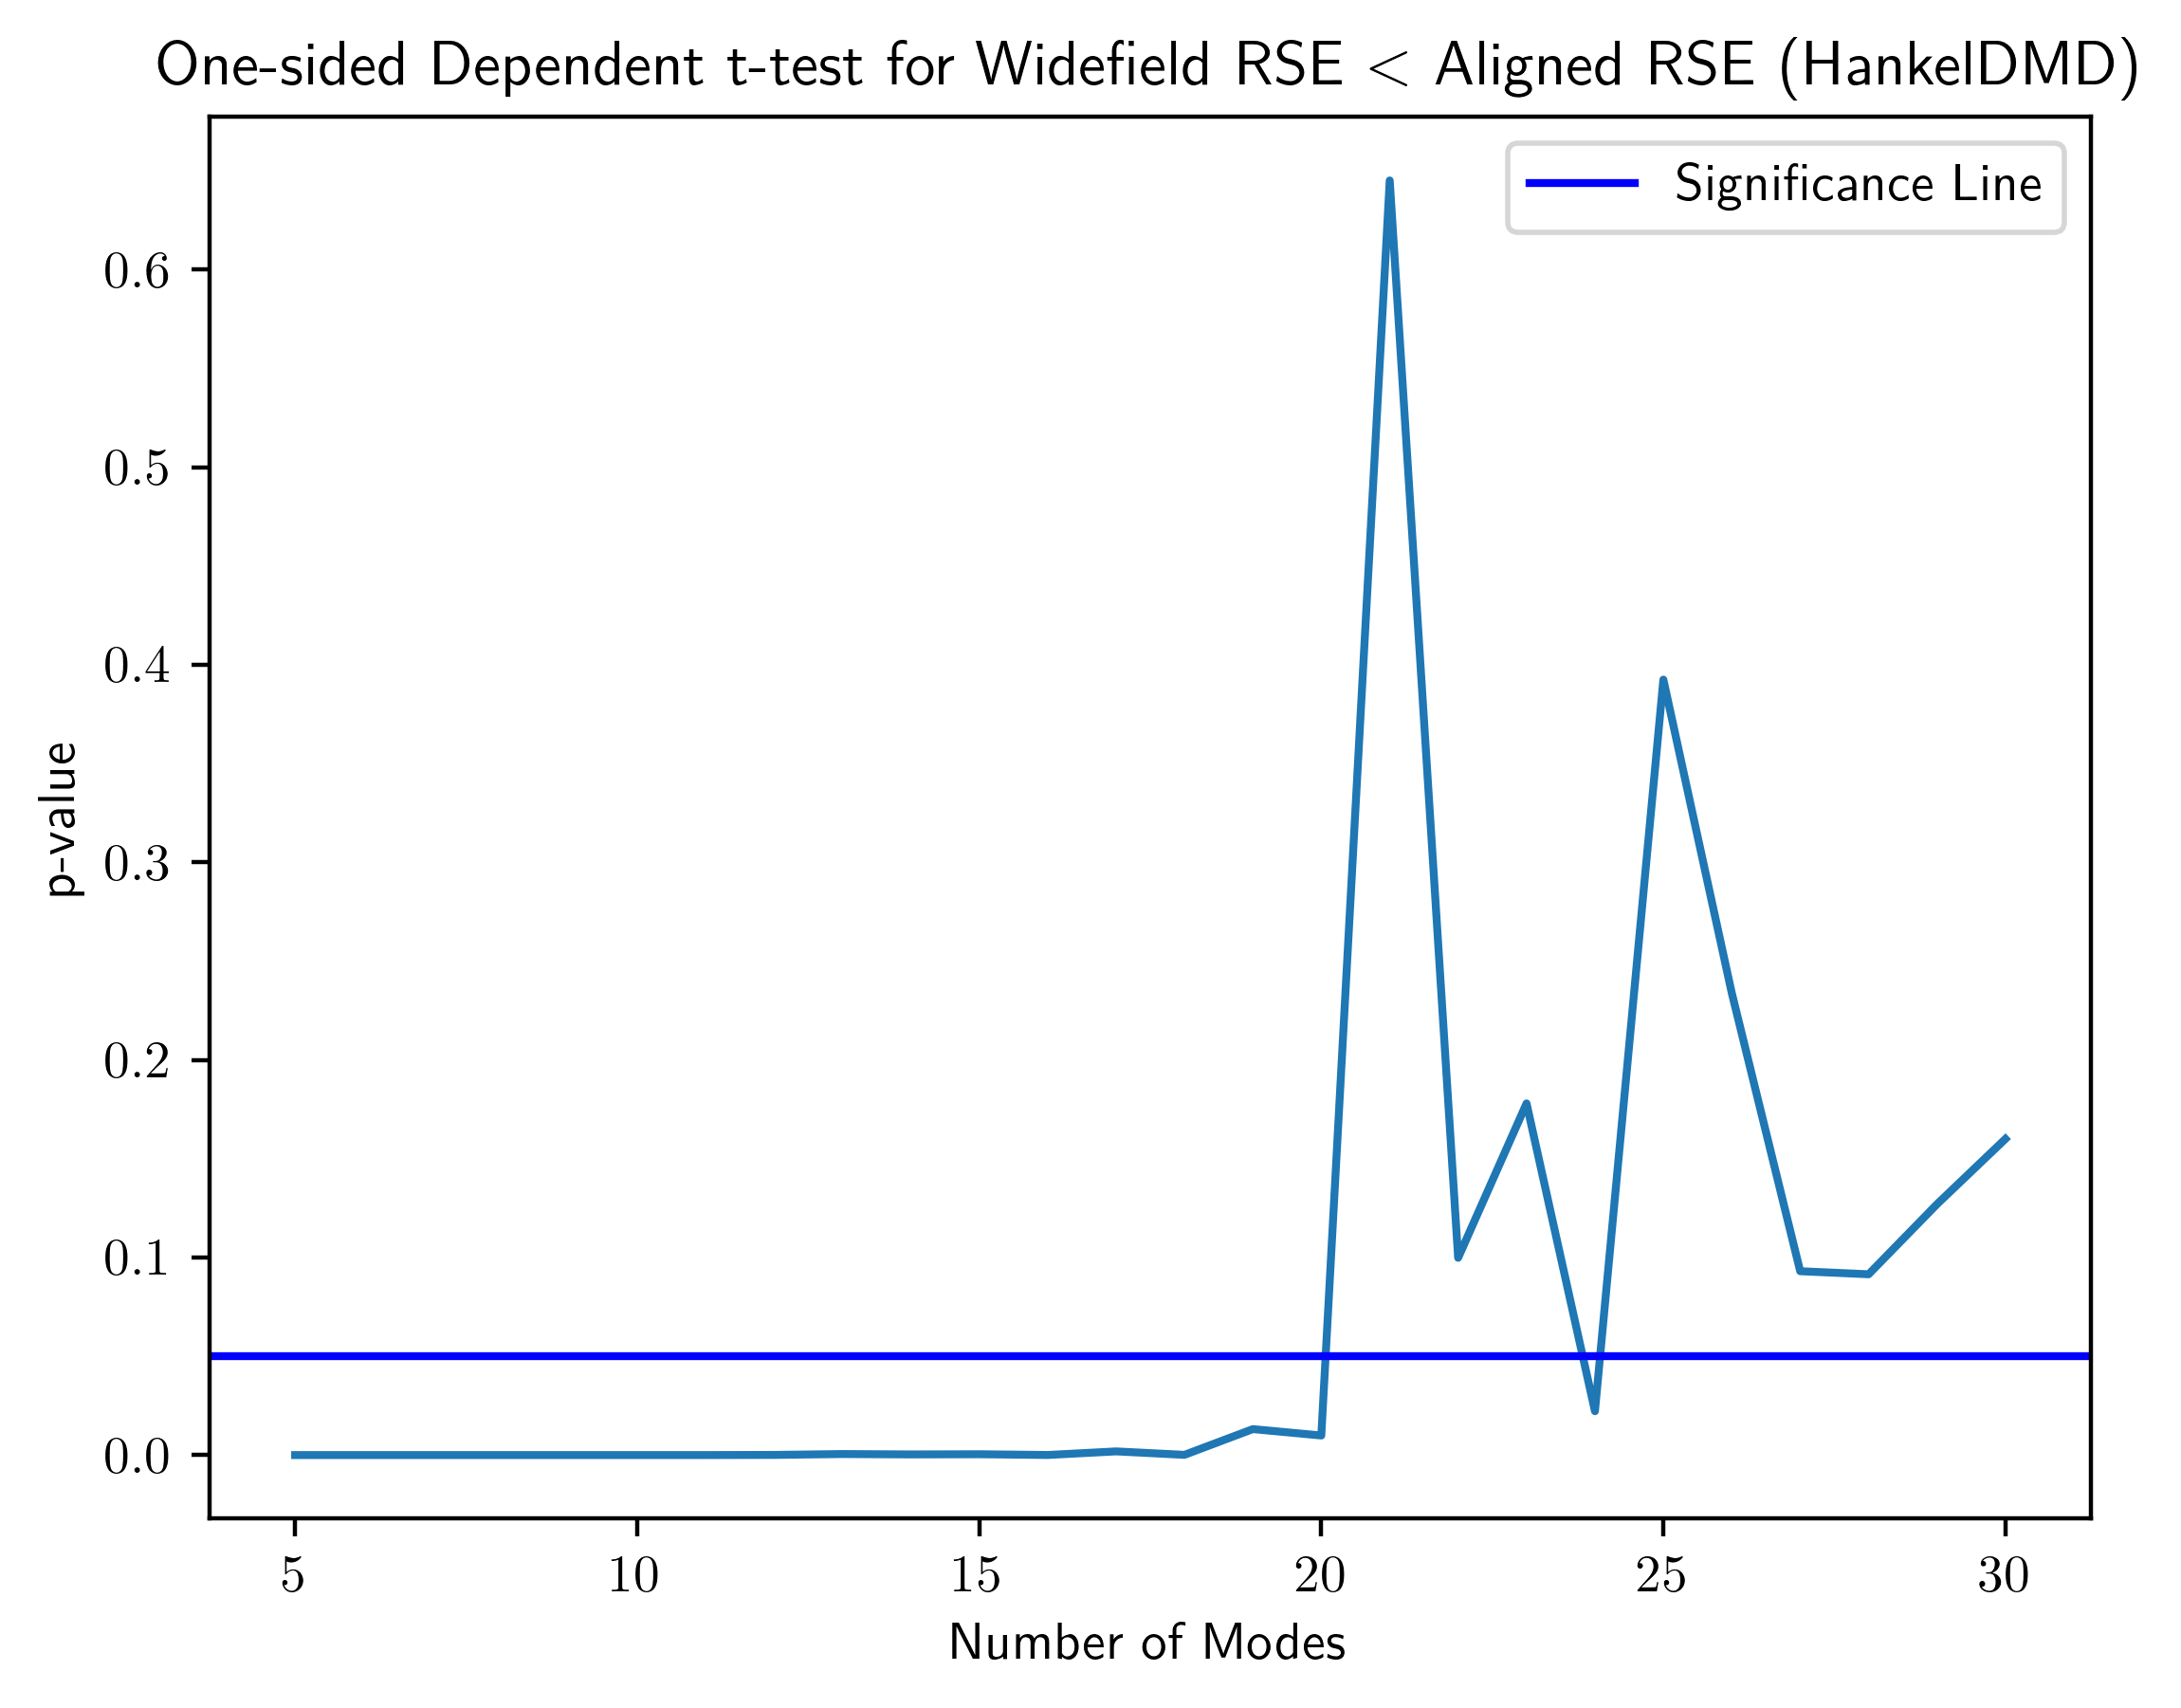

In [11]:
from scipy.stats import ttest_rel
p_values = ttest_rel(total_errors[:,2,:].T,total_errors[:,0,:].T,alternative='less')[1]
plt.plot(np.arange(5,31),p_values)
plt.axhline(0.05,label="Significance Line",color='blue')
plt.xlabel("Number of Modes")
plt.ylabel("p-value")
plt.legend()
plt.title("One-sided Dependent t-test for Widefield RSE $<$ Aligned RSE (HankelDMD)")

We get essentially the same conclusions using HankelDMD.